<a href="https://colab.research.google.com/github/martinn308/AI-FOR-SCIENCE-AND-ENGINEERING-JKUAT/blob/Week-2/Week_6_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Assignment: Discovering Patterns in Data (Clustering)

**Project:** Understanding housing areas (linked to my work on the Kenya Affordable Housing Project).
**Dataset:** The housing dataset from earlier weeks (5,000 rows, USA Housing data used as a stand-in for Kenya data).
**Goal:** Use clustering (unsupervised learning) to find groups of similar areas, without using the price to guide the grouping.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

url = "https://raw.githubusercontent.com/Shivang1179793/House-Price-Prediction/main/housing.csv"
df = pd.read_csv(url)
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


## 1. Select Features
I selected the five numerical features that describe an area. Price is **not** used for clustering. I use it afterwards to describe what the groups look like. Address is left out because it is just text.

In [2]:
features = ["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms",
            "Avg. Area Number of Bedrooms", "Area Population"]
print("Missing values in selected features:", df[features].isna().sum().sum())
df[features].describe()

Missing values in selected features: 0


,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039
std,10657.991214,0.991456,1.005833,1.234137,9925.650114
min,17796.631190,2.644304,3.236194,2.000000,172.610686
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769
max,107701.748378,9.519088,10.759588,6.500000,69621.713378


## 2. Scaling
K-Means works with distances. Population is in the tens of thousands while house age is around 6, so without scaling, population and income would dominate. I use **standardization** (each feature gets a mean of 0 and a standard deviation of 1) so every feature counts equally.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
pd.DataFrame(X_scaled, columns=features).describe().round(2).loc[["mean", "std"]]

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
mean,-0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


## 3. Applying K-Means and Explore Different Numbers of Clusters
I try k = 2 to 8 and look at two measures:
- **Inertia (elbow method):** how tight the clusters are. Lower is tighter, and I look for where the drop slows down.
- **Silhouette score:** how well separated the clusters are, from -1 to 1. Higher is better.

In [4]:
ks = range(2, 9)
inertias, sil_scores = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))

pd.DataFrame({"k": list(ks), "Inertia": inertias, "Silhouette": sil_scores}).set_index("k").round(4)

,Inertia,Silhouette
k,,
2,19798.2636,0.1983
3,17686.2958,0.1587
4,16132.0450,0.1508
5,14844.4872,0.1518
6,13874.7462,0.1466
7,13095.0684,0.1443
8,12370.2023,0.1465


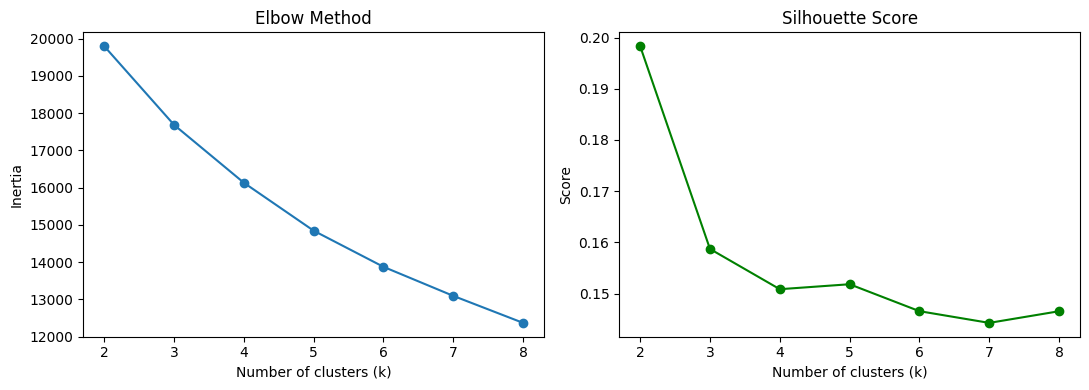

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(ks), sil_scores, marker="o", color="green")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

## 4. Choosing the Number of Clusters
- The silhouette score is highest at **k = 2** (about 0.198), but it is low overall for every k (all below 0.20). This tells me the data does not have strongly separated natural groups.
- The elbow curve falls smoothly with no sharp bend.
- With k = 2, the data is split mostly by house size (rooms and bedrooms) only. With **k = 3**, the groups also separate by income and population, which gives a more useful picture for housing planning, and the silhouette score only drops a little (about 0.159).

**I chose k = 3** as a practical balance between statistical fit and usefulness, and I note that the groups overlap.

In [6]:
k_final = 3
kmeans = KMeans(n_clusters=k_final, n_init=10, random_state=42).fit(X_scaled)
df["Cluster"] = kmeans.labels_
print("Silhouette score for k = 3:", round(silhouette_score(X_scaled, df["Cluster"]), 4))
df["Cluster"].value_counts().sort_index()

Silhouette score for k = 3: 0.1587


,count
Cluster,
0,1729
1,1545
2,1726


## 5. Visualize the Clusters
The data has 5 features, so I use **PCA** to squash it down to 2 dimensions for plotting.

Variance shown in the 2D plot: 49.8 %


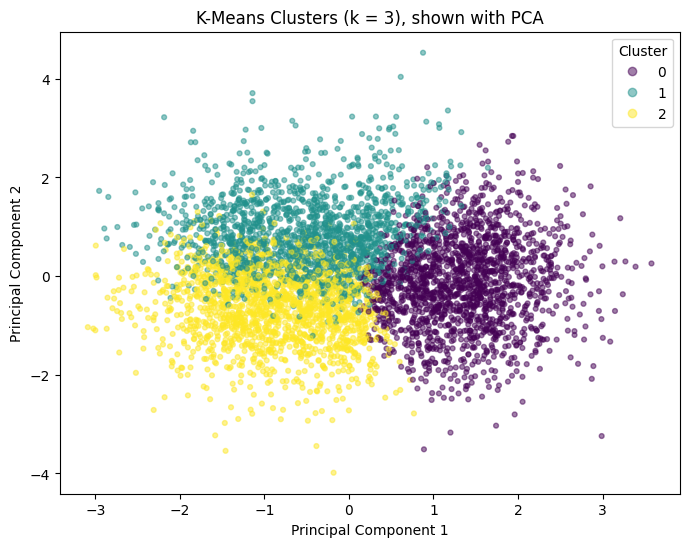

In [7]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
print("Variance shown in the 2D plot:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

plt.figure(figsize=(8, 6))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=df["Cluster"], cmap="viridis", alpha=0.5, s=12)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters (k = 3), shown with PCA")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

## 6. Characteristics of Each Cluster
Average value of each feature per cluster. ***price***
 was not used to build the clusters, it is included only to describe them.

In [8]:
pd.options.display.float_format = "{:,.2f}".format
profile = df.groupby("Cluster")[features + ["Price"]].mean()
profile["Number of Areas"] = df["Cluster"].value_counts().sort_index()
profile

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Number of Areas
Cluster,,,,,,,
0,"69,909.61",6.03,7.90,5.20,"35,100.68","1,364,831.57",1729
1,"60,521.61",5.78,6.74,3.42,"41,890.81","1,080,235.84",1545
2,"74,470.42",6.11,6.29,3.26,"32,101.52","1,234,997.17",1726


In [9]:
profile_scaled = pd.DataFrame(
    kmeans.cluster_centers_, columns=features, index=[f"Cluster {i}" for i in range(k_final)]
)
profile_scaled.round(2)

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
Cluster 0,0.12,0.05,0.91,0.99,-0.11
Cluster 1,-0.76,-0.20,-0.24,-0.45,0.58
Cluster 2,0.55,0.13,-0.69,-0.59,-0.41


## 7. Discussion: What the Groups Might Represent

| Cluster | What stands out | Average price |
|---|---|---|
| **0** | Larger homes (about 7.9 rooms, 5.2 bedrooms), fairly high income, medium population | about 1,364,832 (highest) |
| **1** | Lowest income (about 60,500), highest population (about 41,900), medium-size homes | about 1,080,236 (lowest) |
| **2** | Highest income (about 74,500), smallest homes (about 6.3 rooms, 3.3 bedrooms), lowest population (about 32,100) | about 1,234,997 |

**What they might represent:**
- **Cluster 0: "Spacious family housing areas".** Bigger homes bring the highest prices.
- **Cluster 1: "Dense, lower-income areas".** Many people, lower incomes and the cheapest homes. For affordable housing planning, this is the group where demand for affordable units is likely strongest.
- **Cluster 2: "Higher-income, less crowded areas with compact homes".** High income does not always mean the highest price, because the homes are smaller.

